In [ ]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("hojjatk/mnist-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'mnist-dataset' dataset.
Path to dataset files: /kaggle/input/mnist-dataset


In [ ]:
import os
for root, folder, file in os.walk(path):
  print(f"theres {len(file)} files in {len(folder)} folder, in {root}")

theres 4 files in 4 folder, in /kaggle/input/mnist-dataset
theres 1 files in 0 folder, in /kaggle/input/mnist-dataset/t10k-labels-idx1-ubyte
theres 1 files in 0 folder, in /kaggle/input/mnist-dataset/t10k-images-idx3-ubyte
theres 1 files in 0 folder, in /kaggle/input/mnist-dataset/train-labels-idx1-ubyte
theres 1 files in 0 folder, in /kaggle/input/mnist-dataset/train-images-idx3-ubyte


In [ ]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


(28, 28)

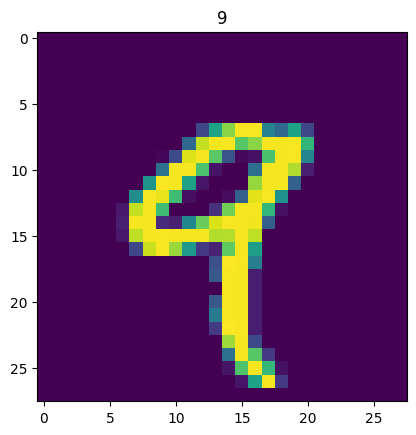

In [ ]:
plt.imshow(X_train[4])
plt.title(y_train[4])
X_train[0].shape

<function matplotlib.pyplot.show(close=None, block=None)>

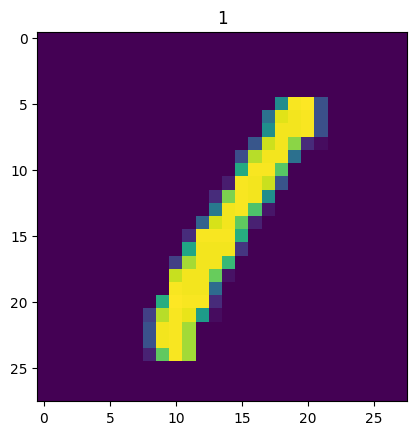

In [ ]:
class_name=["0","1","2","3","4","5","6","7","8","9"]
index=3
plt.imshow(X_train[index])
plt.title(class_name[y_train[index]])
plt.show

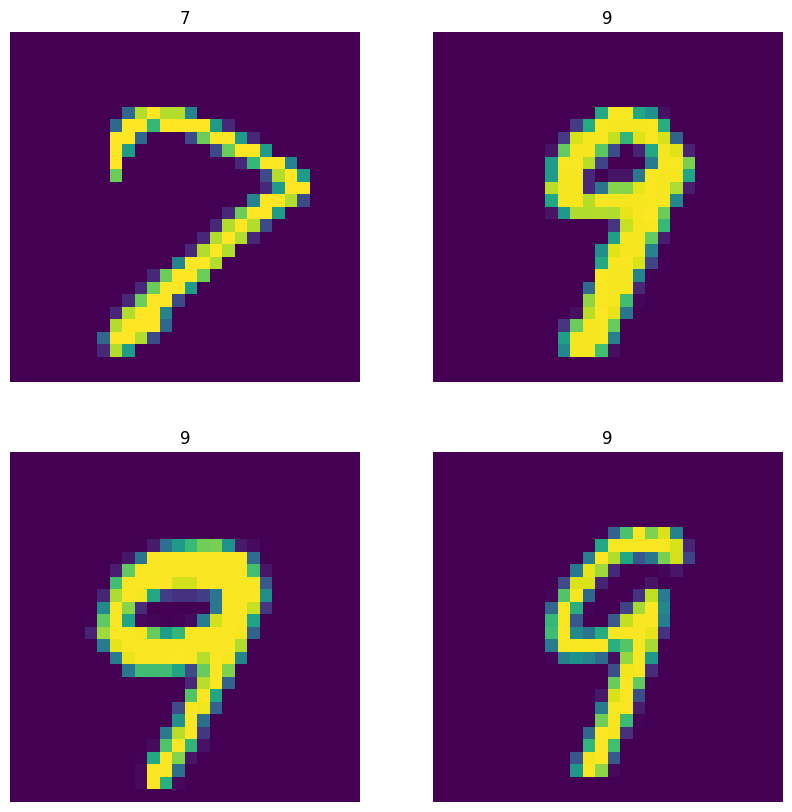

In [ ]:
import random
plt.figure(figsize=(10,10))
for i in range(4):
  ax = plt.subplot(2,2,i+1)
  randindex= random.choice(range(len(X_train)))
  plt.imshow(X_train[randindex])
  plt.title(y_train[randindex])
  plt.axis(False)

In [ ]:
len(X_train), len(y_train) , len(X_test), len(y_test)

(60000, 60000, 10000, 10000)

In [ ]:
X_train_norm = X_train/255.0
X_test_norm = X_test/255.0
X_test_norm.min(), X_test_norm.max()

(np.float64(0.0), np.float64(1.0))

In [ ]:
from tensorflow.keras.layers import Dense,Conv2D,MaxPooling2D, Activation,Flatten
from tensorflow.keras import Sequential
from tensorflow.keras import  optimizers, losses, metrics

tf.random.set_seed(42)
model11 =  tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax")
])

model11.compile(loss=tf.keras.losses.CategoricalCrossentropy(),
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])
history = model11.fit(X_train, tf.one_hot(y_train, depth=10), epochs=10,
            validation_data=(X_test, tf.one_hot(y_test, depth=10)))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.2508 - loss: 2.0646 - val_accuracy: 0.2894 - val_loss: 1.6980
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.3113 - loss: 1.6411 - val_accuracy: 0.3505 - val_loss: 1.5844
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.4079 - loss: 1.4869 - val_accuracy: 0.4351 - val_loss: 1.4402
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.5177 - loss: 1.3368 - val_accuracy: 0.5616 - val_loss: 1.2882
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.5892 - loss: 1.2249 - val_accuracy: 0.6196 - val_loss: 1.2305
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6207 - loss: 1.1707 - val_accuracy: 0.5832 - val_loss: 1.2870
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6622 - loss: 1.0977 - val_accuracy: 0.6912 - val_loss: 1.0849
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.6841 - loss: 1.0296 - 

create the model

In [ ]:
model11.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         3,140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │            50 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,632 (37.63 KB)

 Trainable params: 3,210 (12.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,422 (25.09 KB)

In [ ]:
tf.random.set_seed(42)
model12 =  tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28,28)),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(4, activation="relu"),
    tf.keras.layers.Dense(10,activation="softmax")
])

model12.compile(loss=tf.keras.losses.categorical_crossentropy,
                optimizer=tf.keras.optimizers.Adam(),
                metrics=["accuracy"])
history1 = model12.fit(X_train_norm, tf.one_hot(y_train, depth=10), epochs=10,
            validation_data=(X_test_norm, tf.one_hot(y_test, depth=10)))


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.5035 - loss: 1.4030 - val_accuracy: 0.6919 - val_loss: 0.9148
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7177 - loss: 0.8133 - val_accuracy: 0.7334 - val_loss: 0.7407
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.7449 - loss: 0.7172 - val_accuracy: 0.7477 - val_loss: 0.6876
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7595 - loss: 0.6750 - val_accuracy: 0.7585 - val_loss: 0.6597
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7783 - loss: 0.6500 - val_accuracy: 0.7791 - val_loss: 0.6452
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7907 - loss: 0.6343 - val_accuracy: 0.7860 - val_loss: 0.6351
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.7976 - loss: 0.6238 - val_accuracy: 0.7939 - val_loss: 0.6286
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8052 - loss: 0.6156 - 

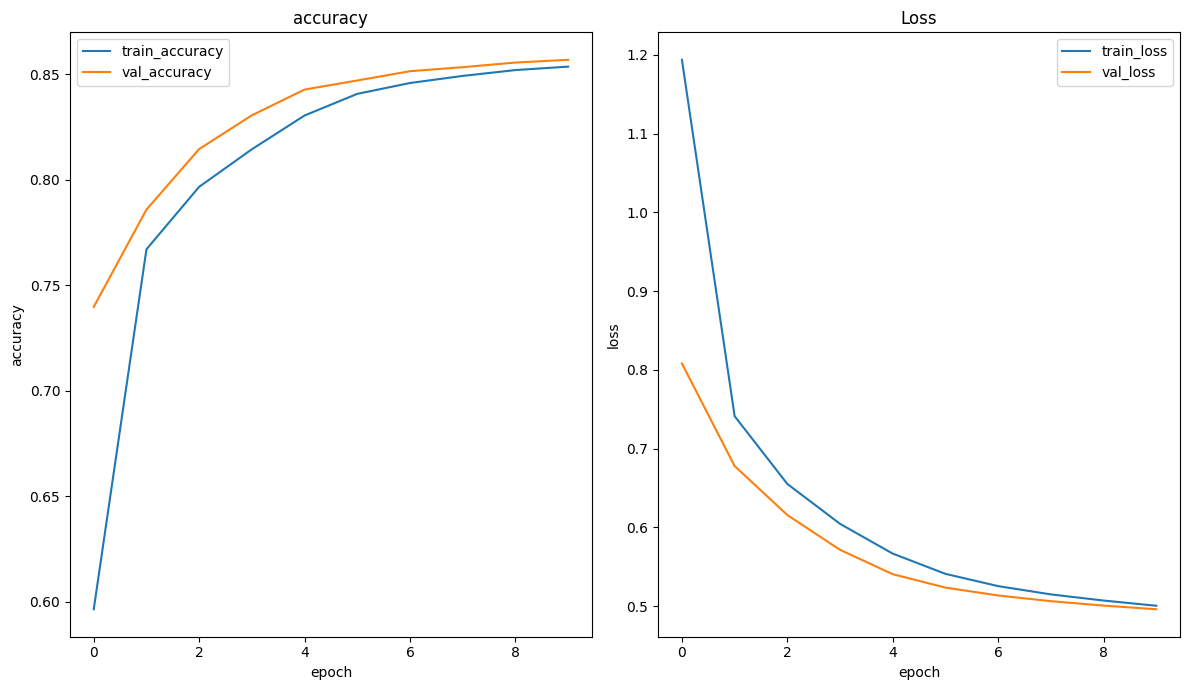

In [ ]:
from prompt_toolkit.shortcuts.progress_bar import Label
def plot_histort(history):
  df = pd.DataFrame(history.history)
  epoch = range(len(df["loss"]))
  fig ,(ax1, ax2) = plt.subplots(1,2,figsize=(12,7))
  ax1.plot(epoch, df['accuracy'], label="train_accuracy")
  ax1.plot(epoch, df['val_accuracy'], label="val_accuracy")
  ax1.set_xlabel("epoch")
  ax1.set_ylabel("accuracy")
  ax1.set_title("accuracy")
  ax1.legend()
  ax2.plot(epoch, df['loss'], label="train_loss")
  ax2.plot(epoch, df['val_loss'], label="val_loss")
  ax2.set_xlabel("epoch")
  ax2.set_ylabel("loss")
  ax2.set_title("Loss")
  ax2.legend()
  plt.tight_layout()
  plt.show()
plot_histort(history1)

In [ ]:
model12.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 4)              │         3,140 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │            20 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │            50 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,632 (37.63 KB)

 Trainable params: 3,210 (12.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 6,422 (25.09 KB)

In [ ]:
model12.evaluate(X_test_norm, tf.one_hot(y_test, depth=10))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8130 - loss: 0.6171


[0.6170843243598938, 0.8130000233650208]

In [ ]:
model12.predict(X_test_norm)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[9.17263038e-04, 1.97589588e-06, 3.53178009e-04, ...,
        9.87255454e-01, 2.47754741e-07, 1.10086203e-02],
       [9.27472301e-03, 4.90632327e-03, 6.19301021e-01, ...,
        2.84795603e-03, 5.51858777e-03, 2.88155279e-03],
       [1.09863356e-06, 8.89280021e-01, 1.82862871e-03, ...,
        1.17457686e-02, 1.91582851e-02, 1.85732283e-02],
       ...,
       [1.52845114e-05, 1.68239910e-06, 1.55781854e-05, ...,
        1.53316685e-03, 2.31949426e-03, 5.45309782e-01],
       [1.12118855e-07, 2.46138165e-06, 5.03234296e-05, ...,
        6.18571444e-11, 3.79517794e-01, 2.65501403e-05],
       [4.33351146e-04, 4.76060707e-17, 1.33471156e-06, ...,
        2.51249585e-12, 1.11709531e-08, 2.98692022e-08]], dtype=float32)

In [ ]:
from PIL import Image
img = Image.open("zero.png")
img =img.convert("L")
img = img.resize((28, 28))
img = np.array(img)
img = img / 255.0
img = np.expand_dims(img, axis=0)
prediction = model12.predict(img)
digit = np.argmax(prediction)
confidence = np.max(prediction)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


In [ ]:
img.shape

(1, 28, 28)

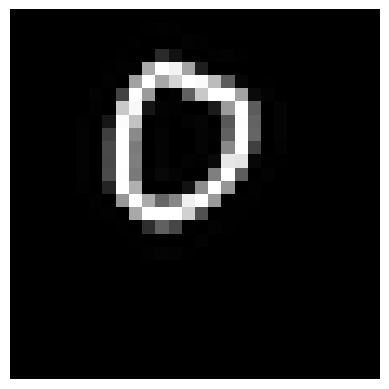

In [ ]:

plt.imshow(img[0], cmap="gray")
plt.axis("off")
plt.show()

In [ ]:
model12.predict(img)      # img shape: (1, 28, 28)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step


array([[1.3376128e-04, 2.5788978e-01, 2.2407729e-02, 2.0936945e-01,
        6.3504484e-03, 3.0717338e-03, 3.0554759e-06, 1.5582441e-01,
        5.0783947e-02, 2.9416570e-01]], dtype=float32)

In [ ]:
class_name = ["0","1","2","3","4","5","6","7","8","9"]

prediction = model12.predict(img, verbose=0)

predicted_class = class_name[np.argmax(prediction)]

print("Predicted digit:", predicted_class)

Predicted digit: 9


In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

class_names = ["0","1","2","3","4","5","6","7","8","9"]

def predict_digit(model, image_path):
    # Load image
    img = Image.open(image_path).convert("L")

    # Resize
    img = img.resize((28, 28))

    # Convert to NumPy
    img = np.array(img)

    # Uncomment if your images have a white background and black digit
    # img = 255 - img

    # Normalize
    img = img / 255.0

    # Display image
    plt.imshow(img, cmap="gray")
    plt.axis("off")
    plt.show()

    # Add batch dimension
    img = np.expand_dims(img, axis=0)

    # Predict
    prediction = model.predict(img, verbose=0)

    predicted_class = np.argmax(prediction)
    confidence = np.max(prediction)

    print(f"Predicted: {class_names[predicted_class]}")
    print(f"Confidence: {confidence:.2%}")

    return predicted_class, confidence

  predict_digit(model12, "digit.png")